## Team Blue - Phase 1

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

import matplotlib.pyplot as plt
import pandas as pd

import json
import datasets
import numpy as np
from tirex2.plotting import plot_forecast

from team_blue import scatter
from team_blue.data_cube import (
    DATA_DIR,
    RESULTS_DIR,
    feature_columns,
    load_dataset_config,
    load_or_build,
)

## Data Aggregation

We integrated Tirex2 in the TIME Testing Framework and ran all experiments via `uv run TIME/experiments/tirex2_model.py --dataset all_datasets --terms short medium long`. <br>

The Time Series Feature were collected from Huggingface https://huggingface.co/datasets/Real-TSF/TIME-Output

In [2]:
# Set force=True to rebuild after new results/features land in output/.
series_cube = load_or_build(force=True)
print("series cube (median/IQR scaled):", series_cube.shape)
series_cube.head()

TiRex2 Australia_Solar/H/long:       45 window rows, feature match 100.00%
TiRex2 Australia_Solar/H/medium:      105 window rows, feature match 100.00%
TiRex2 Australia_Solar/H/short:      315 window rows, feature match 100.00%
TiRex2 Auto_Production_SF/M/short:        5 window rows, feature match 100.00%
TiRex2 CPHL/15T/long:       10 window rows, feature match 100.00%
TiRex2 CPHL/15T/medium:       30 window rows, feature match 100.00%
TiRex2 CPHL/15T/short:      240 window rows, feature match 100.00%
TiRex2 CPHL/30T/long:       20 window rows, feature match 100.00%
TiRex2 CPHL/30T/medium:       60 window rows, feature match 100.00%
TiRex2 CPHL/30T/short:      240 window rows, feature match 100.00%
TiRex2 CPHL/H/medium:       16 window rows, feature match 100.00%
TiRex2 CPHL/H/short:      112 window rows, feature match 100.00%
TiRex2 Coastal_T_S/15T/long:       75 window rows, feature match 100.00%
TiRex2 Coastal_T_S/15T/medium:      225 window rows, feature match 100.00%
TiRex2 Coast

,model,dataset,freq,term,series_idx,variate_idx,model_id,series_name,variate_name,series_start,...,MASE_mean,MASE_median,MASE_std,QR80_rel_mean,QR80_rel_median,QR80_rel_std,n_valid_windows,n_series_total,n_variates_total,has_features
0,TiRex2,Australia_Solar,H,long,0,0,NX-AI/TiRex-2,item0,solar_63726,2021-04-01,...,1.167497,1.203893,0.320425,0.800077,0.813561,0.122141,15,1,3,True
1,TiRex2,Australia_Solar,H,long,0,1,NX-AI/TiRex-2,item0,solar_51616,2021-04-01,...,0.289565,0.277940,0.086836,0.825963,0.813604,0.099297,15,1,3,True
2,TiRex2,Australia_Solar,H,long,0,2,NX-AI/TiRex-2,item0,solar_31378,2021-04-01,...,0.330641,0.219264,0.208663,0.621668,0.589728,0.083612,15,1,3,True
3,TiRex2,Australia_Solar,H,medium,0,0,NX-AI/TiRex-2,item0,solar_63726,2021-04-01,...,1.234361,1.106825,0.470187,0.734794,0.742505,0.117507,35,1,3,True
4,TiRex2,Australia_Solar,H,medium,0,1,NX-AI/TiRex-2,item0,solar_51616,2021-04-01,...,0.328689,0.314660,0.145874,0.751939,0.753504,0.113131,35,1,3,True


In [3]:
print("\n".join(series_cube.columns))

model
dataset
freq
term
series_idx
variate_idx
model_id
series_name
variate_name
series_start
series_length
unique_id
feat_stationarity
feat_x_entropy
feat_trend_strength
feat_trend_stability
feat_trend_hurst
feat_trend_nonlinearity
feat_linearity
feat_curvature
feat_seasonal_strength
feat_seasonal_corr
feat_seasonal_lumpiness
feat_seasonal_entropy
feat_e_acf1
feat_e_acf10
feat_e_diff1_acf1
feat_e_entropy
feat_e_kurtosis
feat_e_shapiro_w
feat_e_arch_lm
feat_spike
feat_mean
feat_std
feat_missing_rate
feat_length
feat_period1
feat_period2
feat_period3
feat_p_strength1
feat_p_strength2
feat_p_strength3
feature_split
dataset_id
task_id
prediction_length
num_windows
num_series
num_variates
seasonality
context_length
test_length
val_length
is_multivariate
first_window_start
last_window_end
MSE_mean
MSE_median
MSE_std
MAE_mean
MAE_median
MAE_std
sMAPE_mean
sMAPE_median
sMAPE_std
MASE_mean
MASE_median
MASE_std
QR80_rel_mean
QR80_rel_median
QR80_rel_std
n_valid_windows
n_series_total
n_variates

## Feature vs. Result Scatter

Filter by dataset and term (multi-select, with *All* / *None* buttons), color by dataset or term, and pick a `feat_*` column for x and a result metric for y. *Aggregate per dataset* plots one point per dataset (the median over all its selected series, frequencies and terms) instead of one point per series; when colored by term, each dataset gets one point per term.

In [4]:
scatter.feature_scatter(series_cube)

## Anaylze Plots

A short summary of the found patterns. The most relevant time-series features of the input data for explaining the performance of tirex-2 seem to be following:
- Autocorrelation at lag 1 (ACF1): Describes the linear correlation between one value and its predecessor. 1 means strong positive relation, -1 mean strong negative relation, 0 means no linear relation
- Seasonal Strength: Describes the ratio between the seasonal component and the residuals of a STL decomposition. 1 means the seasonality explains most of the signal and the resulting residuals are small, while 0 means no seasonality
- Trend Strength: Descibres the ratio between the trend component and the residual of a STL decomposition. 1 means the trend explains most of the signal and the resulting residuals are small, while 0 means no trend.
- Entropy: Describe the randomness or explainability of the next step in a time series. 1 means high noise and the forecasting is hard to explain based on the time series, while 0 means high signal-to-noise ratio and the signal is easy to forecast



### Entropy

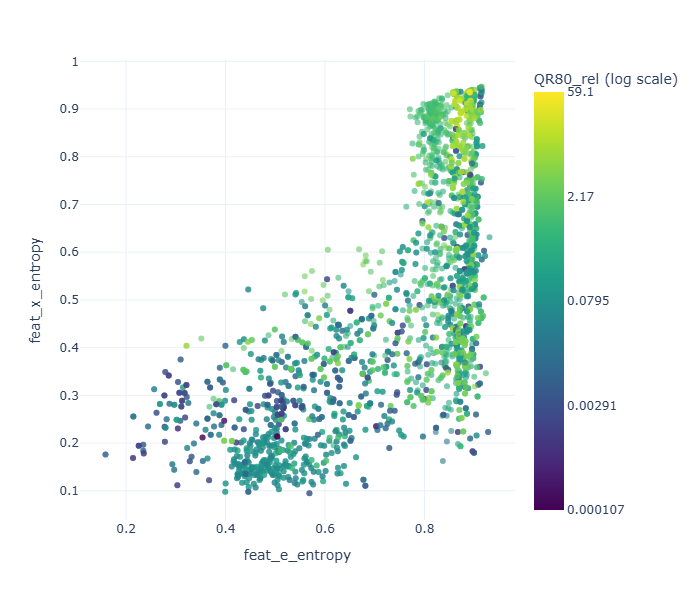

In the entropy plot we can clearly observe the uncertainty of the prediction and correlatet with the entropy of the input, which is something we would expect to observe. So a nice plausiblity check!

### Trend Strength vs Seasonal Strength

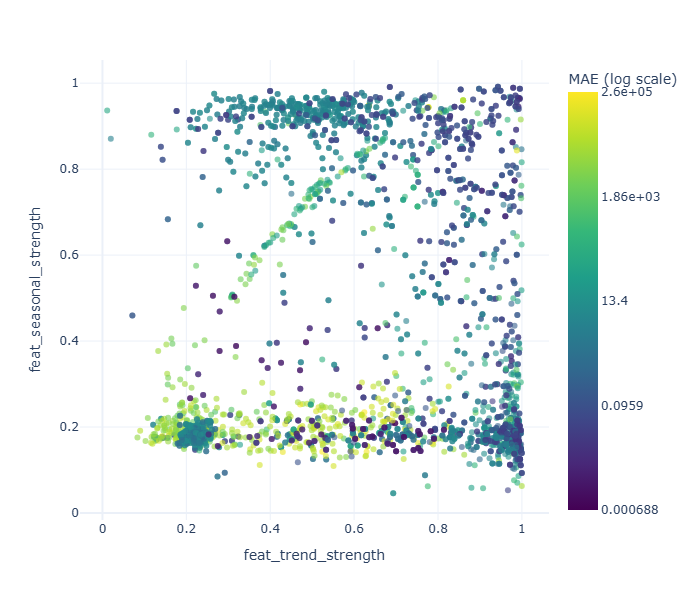
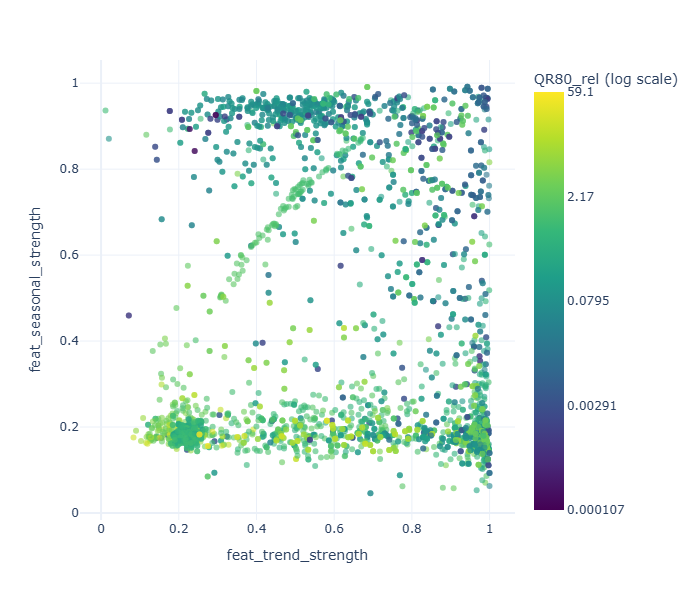

Something we can observe is that the seasonal strength is something that influences the confidence and error of the of the prediction, while the trend strength spread the data points nicely but does not influence the ouput of the model too strongly. An insteresting cluster seem to be the purple dots in the lower left corner, which are all from the current_velocity subset. These sample achieve a low error but have an high uncertainty, which makes them an interesting group to examine further.

### ACF1 vs Trend Strength

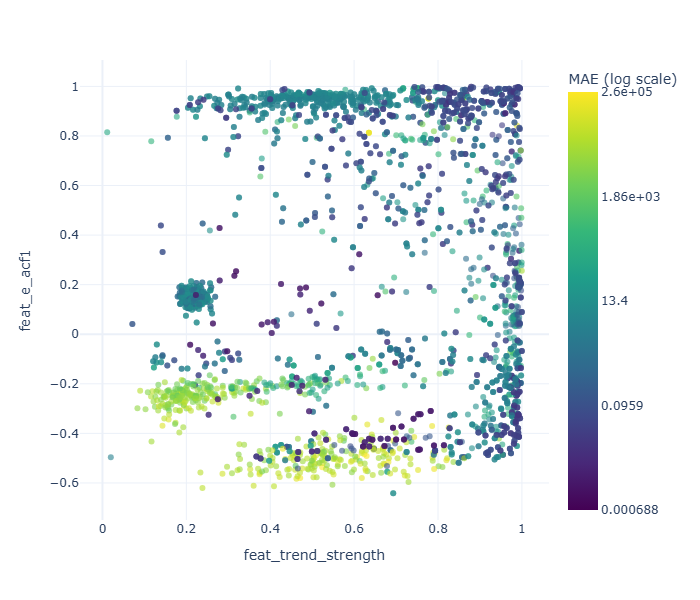
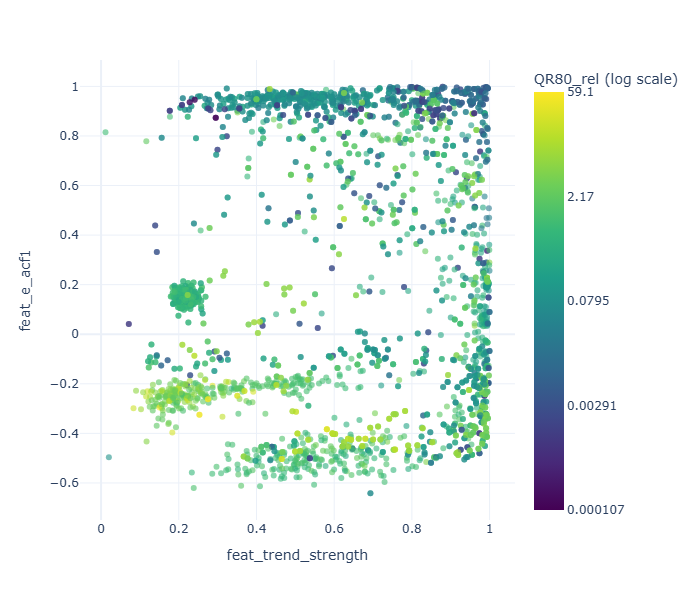



The ACF1 features seems to also be a good indicator for the performance of the model. Tirex-2 seems to be to have lower errors on time series with a positive ACF1, compared to time series with a negative ACF1. Although this effect vanishes with the trend strength. The current_velocity subset can be again observed as an outlier with low MAE and high QR80 at low ACF1 and low Trend Strength.  

### Correction Current_Velocity

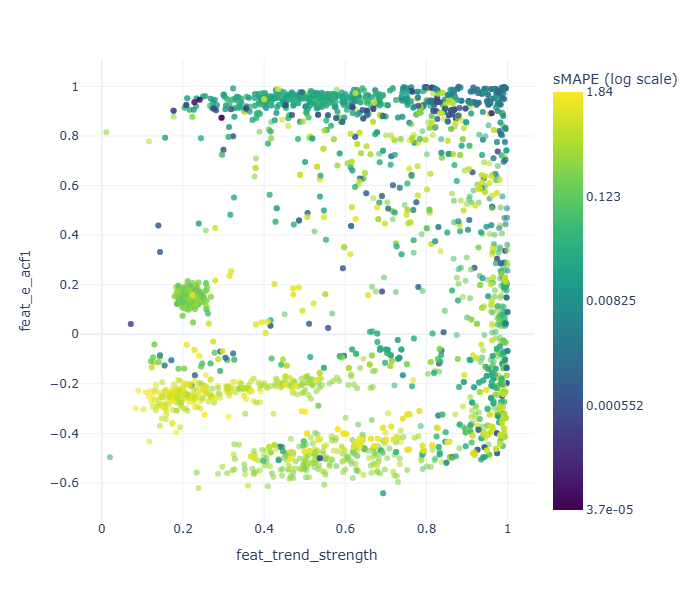
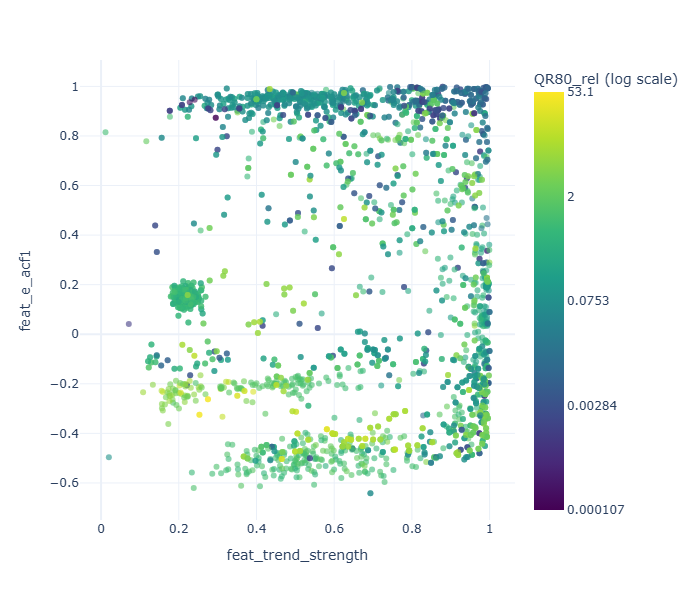

Regarding the current_velocity subset, the cluster of high QR80 is actually a numerical artifact, since a number of samples for this subset have a median near zero. Since we use the relative quantile range (divded by the median), the QR80 explodes with realy small medians. Correcting this by dividing by the inter quantile range (IQR) and using the sMAPE metric instead of the MAE, the effect of the acf1 features is consistend over the dataset.

### Checking the Trend Strength Axis

Before reading more into the trend strength axis, we checked what feature
correlates with trend strength and more detailed, whether the pattern also holds within a single dataset and not just for the whole cube.

trend strength vs:
feat_linearity          0.01
feat_curvature         -0.09
feat_trend_stability    0.83
feat_spike             -0.58
feat_x_entropy         -0.52

size of the trend (absolute value):
feat_linearity 0.64
feat_curvature 0.59

                      sMAPE  MASE  % MASE > 1
feat_trend_strength                         
(0.0, 0.2]            0.17  0.67        5.72
(0.2, 0.4]            0.13  0.71        6.28
(0.4, 0.6]            0.06  0.65        9.78
(0.6, 0.8]            0.10  0.74       20.50
(0.8, 0.95]           0.12  0.78       31.54
(0.95, 1.0]           0.07  0.87       42.60


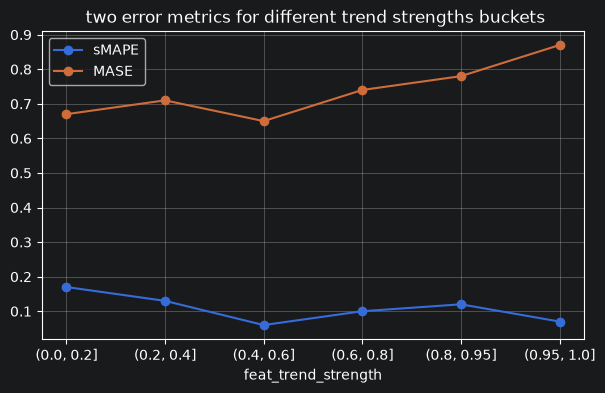

In [5]:
ts = "feat_trend_strength"
rho = series_cube[feature_columns(series_cube)].corr(method="spearman")[ts]
print("trend strength vs:")
print(rho[["feat_linearity", "feat_curvature", "feat_trend_stability",
           "feat_spike", "feat_x_entropy"]].round(2).to_string())
print("\nsize of the trend (absolute value):")
for f in ["feat_linearity", "feat_curvature"]:
    print(f, round(series_cube[ts].corr(series_cube[f].abs(), method="spearman"), 2))

bins = pd.cut(series_cube[ts], [0, 0.2, 0.4, 0.6, 0.8, 0.95, 1.0])
grp = series_cube.groupby(bins, observed=True)
summary = pd.DataFrame({
    "sMAPE": grp["sMAPE_mean"].median(),
    "MASE": grp["MASE_mean"].median(),
    "% MASE > 1": grp["MASE_mean"].apply(lambda s: (s > 1).mean() * 100),
}).round(2)
print("\n", summary)

summary[["sMAPE", "MASE"]].plot(marker="o", figsize=(7, 4), grid=True,
                                title=" two error metrics for different trend strengths buckets")
plt.xlabel("feat_trend_strength")
plt.savefig("plots/trend_strength_check.png", dpi=150, bbox_inches="tight")

In [6]:
# does the pooled correlation also hold within a single dataset but between the different series??
within = series_cube.groupby("dataset", observed=True).apply(
    lambda g: g[ts].corr(g["MASE_mean"], method="spearman") if len(g) >= 20 else None,
    include_groups=False,
).dropna()
print("pooled:", round(series_cube[ts].corr(series_cube["MASE_mean"], method="spearman"), 2))
print("median inside a dataset:", round(within.median(), 2))
print("range:", round(within.min(), 2), "to", round(within.max(), 2))

pooled: 0.12
median inside a dataset: -0.01
range: -0.96 to 0.45


             sMAPE_mean  MASE_mean  sMAPE_mean_within  MASE_mean_within
bin                                                                    
(0.0, 0.2]         0.17       0.67               1.30              0.96
(0.2, 0.4]         0.13       0.71               0.98              1.02
(0.4, 0.6]         0.06       0.65               0.80              1.00
(0.6, 0.8]         0.10       0.74               0.91              1.04
(0.8, 0.95]        0.12       0.78               1.08              1.04
(0.95, 1.0]        0.07       0.87               0.98              1.02


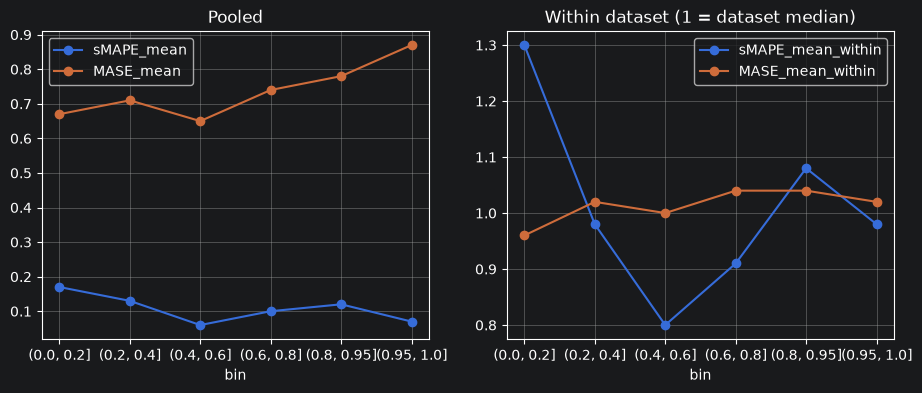

In [7]:
#we compare sMAPE and MASE for the same bins within the dataset
metrics = ["sMAPE_mean", "MASE_mean"]
d = series_cube.dropna(subset=[ts, *metrics]).copy()
d["bin"] = pd.cut(d[ts], [0, 0.2, 0.4, 0.6, 0.8, 0.95, 1.0])

# to normalize within we divide it by the median of its own dataset (1.0 = normal for that dataset)
for m in metrics:
    d[m + "_within"] = d[m] / d.groupby("dataset", observed=True)[m].transform("median")

columns = [*metrics, *[m + "_within" for m in metrics]]
table = d.groupby("bin", observed=True)[columns].median().round(2)
print(table)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
table[metrics].plot(ax=axes[0], marker="o", grid=True, title="Pooled")
table[[m + "_within" for m in metrics]].plot(
    ax=axes[1], marker="o", grid=True, title="Within dataset (1 = dataset median)"
)
fig.savefig("plots/trend_strength_pooled_vs_within.png", dpi=150, bbox_inches="tight")

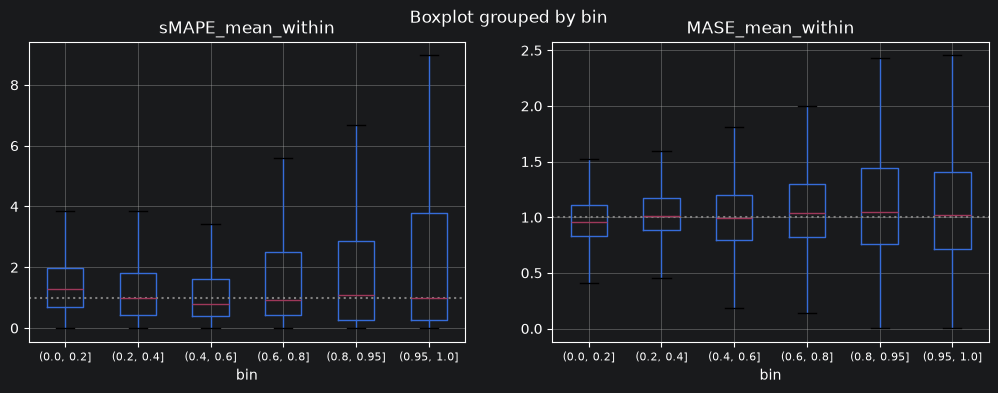

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, m in zip(axes, metrics):
    d.boxplot(column=m + "_within", by="bin", ax=ax, showfliers=False)
    ax.axhline(1, color="grey", ls=":")
    ax.tick_params(axis="x", labelsize=8)
fig.savefig("plots/trend_strength_boxplots.png", dpi=150, bbox_inches="tight")

#### Top 10% vs bottom 10% trend strength

In [9]:
metrics_all = ["MAE_mean", "MSE_mean", "sMAPE_mean", "MASE_mean", "QR80_rel_mean"]
d_all = series_cube.dropna(subset=[ts])
low_cut, high_cut = d_all[ts].quantile([0.1, 0.9])
low, high = d_all[d_all[ts] <= low_cut], d_all[d_all[ts] >= high_cut]

cmp = pd.DataFrame({"bottom 10%": low[metrics_all].median(),
                    "top 10%": high[metrics_all].median()})
cmp["ratio"] = (cmp["top 10%"] / cmp["bottom 10%"]).round(2)
print(cmp.round(3))
print("\nshare with MASE > 1:  bottom {:.1f}%   top {:.1f}%".format(
    (low["MASE_mean"] > 1).mean() * 100, (high["MASE_mean"] > 1).mean() * 100))

print("\nbut the two groups are different datasets:")
print(pd.DataFrame({"bottom": low["dataset"].value_counts().head(3),
                    "top": high["dataset"].value_counts().head(3)}).fillna(0).astype(int))

               bottom 10%  top 10%  ratio
MAE_mean            0.627    0.284   0.45
MSE_mean            1.202    0.160   0.13
sMAPE_mean          0.142    0.082   0.57
MASE_mean           0.634    0.836   1.32
QR80_rel_mean       2.053    0.812   0.40

share with MASE > 1:  bottom 5.8%   top 39.1%

but the two groups are different datasets:
                  bottom  top
dataset                      
Coastal_T_S            0   83
Global_Price           0   59
azure2019_D          469    0
azure2019_I          283    0
azure2019_U           25    0
current_velocity       0  304


In [10]:
# same split, but inside each dataset separately
rows = []
for name, g in d_all.groupby("dataset", observed=True):
    lo_c, hi_c = g[ts].quantile([0.1, 0.9])
    lo, hi = g[g[ts] <= lo_c], g[g[ts] >= hi_c]
    if len(lo) >= 4 and len(hi) >= 4:
        rows.append({m: hi[m].median() / lo[m].median() for m in metrics_all})

paired = pd.DataFrame(rows)
print(f"top/bottom ratio inside a dataset (median over {len(paired)} datasets):")
print(paired.median().round(2).to_string())

top/bottom ratio inside a dataset (median over 16 datasets):
MAE_mean         1.17
MSE_mean         1.75
sMAPE_mean       0.65
MASE_mean        1.01
QR80_rel_mean    0.70


Trend strength results (just most notably numbers above expressed in text)

Trend strength tells us how strong the trend is compared to the noise. This comes form the correlation with the other features. It has no correlation with signed linearity (0.01), but a clear one with the size of linearity (0.64) and curvature (0.59). It also goes along with trend stability (0.83), and negatively with spike (-0.58) and entropy (-0.52), so smooth series score high.

Over all datasets, MASE goes up from 0.67 to 0.87 with higher trend strength, and the share of series with MASE above 1 goes from 6% to 43%. But it appears that that comes mostly from the datasets being different, because the correlation is only 0.12 pooled and -0.01 inside a dataset, ranging from -0.96 to 0.45. Cause when we compare each series to the median of its own dataset, MASE stays flat between 0.96 and 1.04, so this means that there is not really a consistent effect of trend strength on the error. This is no proof that there is no effect, because many datasets only cover a small part of the trend strength range.

sMAPE jumps up and down in a W shape, but the spread inside one bin is way bigger than these jumps, so we dont interprete that detailed. What is interesting is that the spread gets bigger with higher trend strength: the middle 50% of MASE goes from 0.28 wide to about 0.70 wide. So the typical error stays the same, but the results vary much more between series.

So trend strength itself does not seem to explain the error of the model. What it does change is the confidence of the model. Inside a dataset, where we looked a bit detailed, the series with the highest trend strength have about 30% narrower intervals than the ones with the lowest (ratio 0.70), while MASE stays the same (ratio 1.01). Series that are smoother have narrower intervals, and the link with entropy is even clearer. This is expedted.

### Looking at Real Forecasts

Now choose to do a different approach and compare actual forecasts from the bottom 10% and the top 10% of trend strength, each with low MASE (< 0.7) and high MASE (> 1.1) (choosen). Blue is the previous data, dashed blue the future truth, red the forecast with its 10-90% interval. I choose to always plot the middle forecast window and show at most its first 24 steps, cause first the long forecasts were not visible good enough.

rows with low / high MASE
low trend 578 31
high trend 322 271
                          n  share_high_MASE
group      seasonality                      
high trend 1             29             0.90
           4             59             0.69
           5             52             1.00
           12            41             0.20
           24            93             0.45
           48             3             0.00
           72           210             0.19
           96           149             0.18
           144           22             0.05
           288          151             0.23
low trend  1             19             0.11
           12             1             0.00
           24             6             0.67
           288          783             0.03


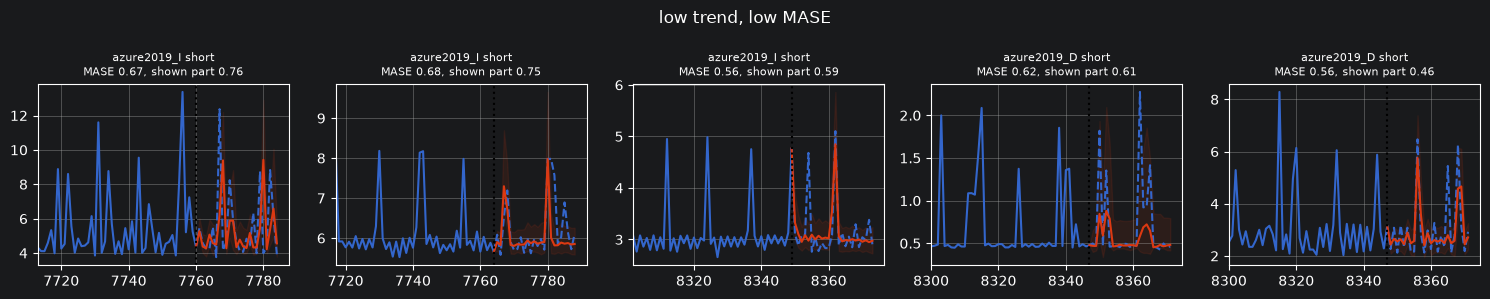

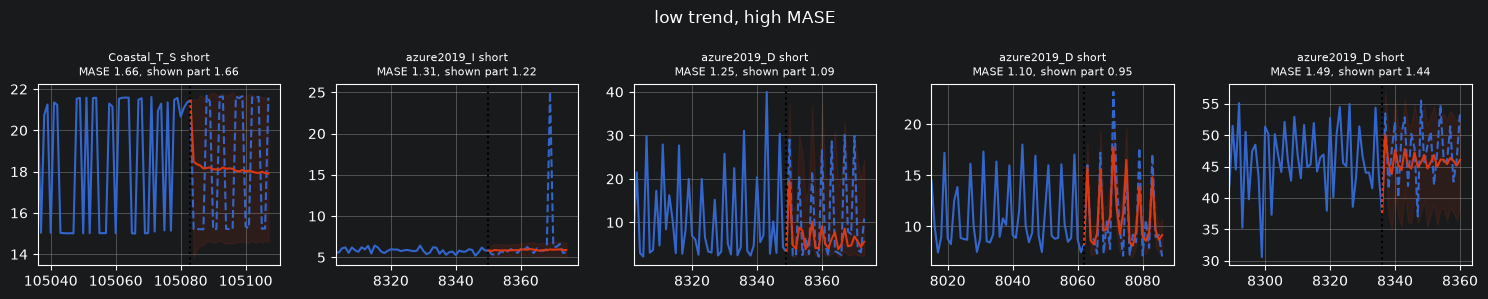

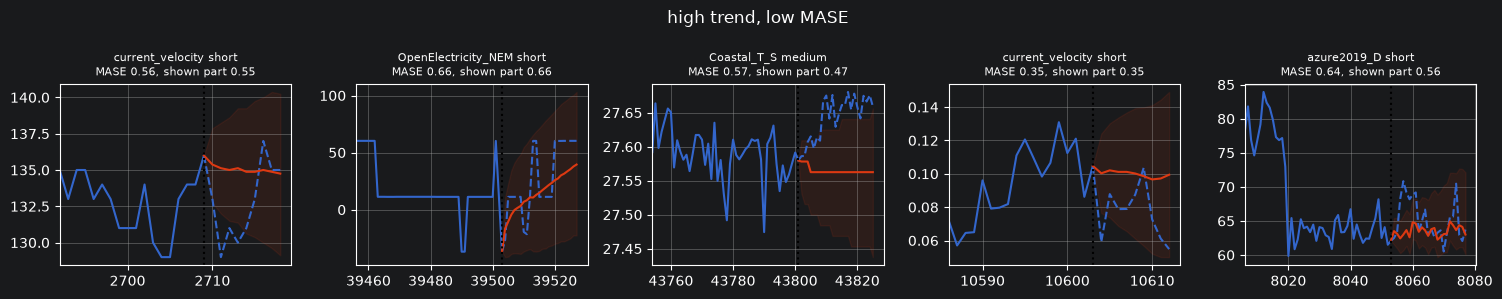

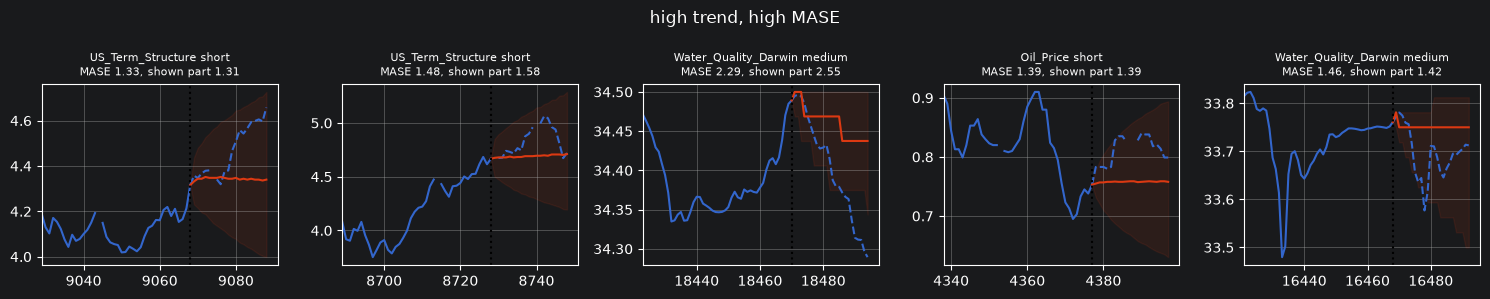

In [11]:
def show(rows, title, k=5):
    fig, axes = plt.subplots(1, k, figsize=(15, 3))
    used = 0
    for r in rows.sample(frac=1, random_state=0).itertuples():
        run = RESULTS_DIR / "TiRex2" / str(r.dataset) / str(r.freq) / str(r.term)
        config = json.loads((run / "config.json").read_text())
        pl = config["prediction_length"]
        n = min(pl, 24)  # only the first 24 steps, otherwise long forecasts can't be read

        name = f"{r.dataset}/{r.freq}"
        target = datasets.load_from_disk(str(DATA_DIR / name))[int(r.series_idx)]["target"]
        series = np.atleast_2d(np.array(target, dtype=float))[r.variate_idx]
        test_start = len(series) - load_dataset_config()[name]["test_length"]

        forecast = np.load(run / "predictions.npz")["predictions_quantiles"].astype(float)
        forecast = forecast[r.series_idx, :, :, r.variate_idx] * config["prediction_scale_factor"]

        # MASE of the visible part of each window, then plot the window closest to the series average
        metrics = np.load(run / "metrics.npz")
        scale = (metrics["MAE"] / metrics["MASE"])[r.series_idx, :, r.variate_idx]
        shown = np.array([
            np.nanmean(np.abs(forecast[w, 4, :n] - series[test_start + w * pl:][:n])) / scale[w]
            for w in range(len(scale))
        ])
        window = int(np.nanargmin(np.abs(shown - r.MASE_mean)))
        if abs(shown[window] - r.MASE_mean) > 0.2 * r.MASE_mean:
            continue  # no window looks like this series' average, so skip it
        ax = axes[used]
        start = test_start + window * pl

        plot_forecast(series[:start], forecast[window, :, :n], series[start:start + n],
                      engine="matplotlib", max_context_to_show=2 * n, ax=ax)
        ax.set_title(f"{r.dataset} {r.term}\nMASE {r.MASE_mean:.2f}, shown part {shown[window]:.2f}", fontsize=8)
        ax.get_legend().remove()
        used += 1
        if used == k:
            break
    fig.suptitle(title)
    fig.tight_layout()

    fig.savefig(f"plots/forecasts_{title.replace(', ', '_').replace(' ', '_')}.png", dpi=150, bbox_inches="tight")


# trend series uqantiles filter
low = series_cube[series_cube[ts] <= series_cube[ts].quantile(0.1)]
high = series_cube[series_cube[ts] >= series_cube[ts].quantile(0.9)]
print("rows with low / high MASE")
for name, group in [("low trend", low), ("high trend", high)]:
    good, bad = group[group["MASE_mean"] < 0.7], group[group["MASE_mean"] > 1.1]
    print(name, len(good), len(bad))
    show(good, f"{name}, low MASE")
    show(bad, f"{name}, high MASE")

both = pd.concat([low.assign(group="low trend"), high.assign(group="high trend")])
print(both.groupby(["group", "seasonality"])["MASE_mean"].agg(n="size", share_high_MASE=lambda s: (s > 1.1).mean()).round(2))


Forecast results

One interesting thing to mention is that high MASE is rare at low trend strength (31 series against 578 with low MASE), but rather ocmmon or even distributied at high trend strength (271 against 322). (with low MASE < 0.7 and high MASE > 1.1)

Spiky data alone doesnt seem to be a problem. In the low trend, low MASE plots the model predicts regular spikes at the right time. The failures look different depending on the trend. At low trend strength the series jumps around a stable level. One example is Coastal_T_S, which switches between two levels and the forecast stays flat in the middle. At high trend strength the level moves away, for example in US_Term_Structure the forecast stays almost flat at the last value while the truth drifts off. Some high MASE plots seem to even follow the truth quite well in the visible part (like Global_Influenza and current_velocity).

MASE has to be read carefully though. It only means the error is small compared to how much the series changes over one season. The categorized MASE in the plot title is the average over all windows, while the plot shows just one. A low MASE does not automatically mean a good forecast. It is clearly visible that in the high trend, low MASE plots the forecast is often nearly flat. On the other hand a high MASE does not have to mean a bad one either.